# Slide 18b: one KBM, the 95% extent of $\phi$ and $A_\parallel$ against WIDTH (raw radians, not normalised)

Fusion_PhD-qp5.31 (STEP GK talk, 2 Nov 2026). Companion of slide 18, same leaves and NBASIS: TGLF (FILTER 2) top row, GFTM (stock,
FILTER 0.5) bottom row; one column per field. Extent = pyro `Extent` at 95%, the $\theta$ range holding 95% of $|{\rm field}|^2$,
in radians and **not** divided by GS2's (user: "please don't normalise the kbm extent"). The two fields have different widths,
so each panel carries GS2's extent of its own field (black dashed). GS2's extents come from the complex re-save of slide 17.
WIDTH is the one Hermite width given to the code; the codes' $\phi$ and $A_\parallel$ extents are each free to differ from it and
from each other. Runs with no unstable mode are left out.

In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
# slide-readable at the saved size, white background (user, 2026-11-01)
plt.rcParams.update({"font.size": 20, "axes.labelsize": 22, "axes.titlesize": 22, "xtick.labelsize": 20, "ytick.labelsize": 20,
                     "legend.fontsize": 19, "lines.linewidth": 2.5, "lines.marker": "", "figure.facecolor": "white",
                     "axes.facecolor": "white", "savefig.facecolor": "white", "savefig.dpi": 200})
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
plots_dir = ROOT / "Plots" / "stepgk_20261102"
plots_dir.mkdir(parents=True, exist_ok=True)


def log_xticks(ax, ticks):
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()
import json
import pandas as pd
from pyrokinetics import PyroHypercube
from pyrokinetics.diagnostics.extent import Extent

single_root = Path(os.environ["GYRO_DATA_OUTPUT"])     # GyroRun wrote the single-mode scans to the scratch tree
leaves = {"TGLF": single_root / "TGLF/Runs/single_mode_spr045/SPR-045/fixed_width_f2_sample_0818",
          "GFTM": single_root / "GFTM/Runs/single_mode_spr045/SPR-045/galF_sample_0818"}
shown_nbasis = {"TGLF": [8, 16, 32], "GFTM": [8, 16, 32, 64]}
field_labels = {"phi": r"$\phi$", "apar": r"$A_\parallel$"}
fraction = 0.95

gs2_scan = PyroHypercube.from_directory(single_root / "GS2/Runs/LATIN_HYPERCUBE/SPR-045/kbm_free", pattern="sample_0818", params=["ky"],
                                        gk_code="GS2", file_name="input.in")
gs2_scan.load_gk_output(netcdf_file=single_root / "GS2/Runs/single_mode_spr045/SPR-045/complex_sample_0818/pyroscan.nc")
Extent(gs2_scan.gk_output, fraction=fraction)
extent_gs2 = {field: float(gs2_scan.gk_output.data.extent.sel(field=field).pint.dequantify().squeeze()) for field in field_labels}
print("GS2 extent (rad):", {field: round(value, 3) for field, value in extent_gs2.items()})

GS2 extent (rad): {'phi': 1.638, 'apar': 2.258}


In [2]:
runs = []
for code, leaf in leaves.items():
    scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    print(code, json.loads((leaf / "manifest.json").read_text())["code_flags"])
    Extent(scan.gk_output, fraction=fraction)
    output = scan.gk_output.data.pint.dequantify().squeeze("ky", drop=True)      # one ky per run
    dominant = output.isel(mode=output.growth_rate.fillna(-np.inf).argmax("mode"))   # dominant mode = argmax growth rate
    runs.append(pd.DataFrame(dict(code=code, width=output.WIDTH.values.astype(float), nbasis=output.NBASIS_MAX.values.astype(int),
                                  gamma=dominant.growth_rate.values,
                                  **{f"extent_{field}": dominant.extent.sel(field=field).values for field in field_labels})))
runs = pd.concat(runs).sort_values(["code", "nbasis", "width"])

TGLF {'FILTER': 2.0, 'THETA_TRAPPED': 0.7, 'NXGRID': 32, 'NMODES': 4, 'USE_BPER': True, 'USE_TRANSPORT_MODEL': False, 'WRITE_WAVEFUNCTION_FLAG': 1, 'FIND_WIDTH': False}


GFTM {'FILTER': 0.5, 'FIND_WIDTH': False, 'NMODES': 4, 'IBRANCH': -1, 'USE_TRANSPORT_MODEL': False, 'USE_BPER': True, 'WRITE_WAVEFUNCTION_FLAG': 1, 'FIELD_GALERKIN': False}


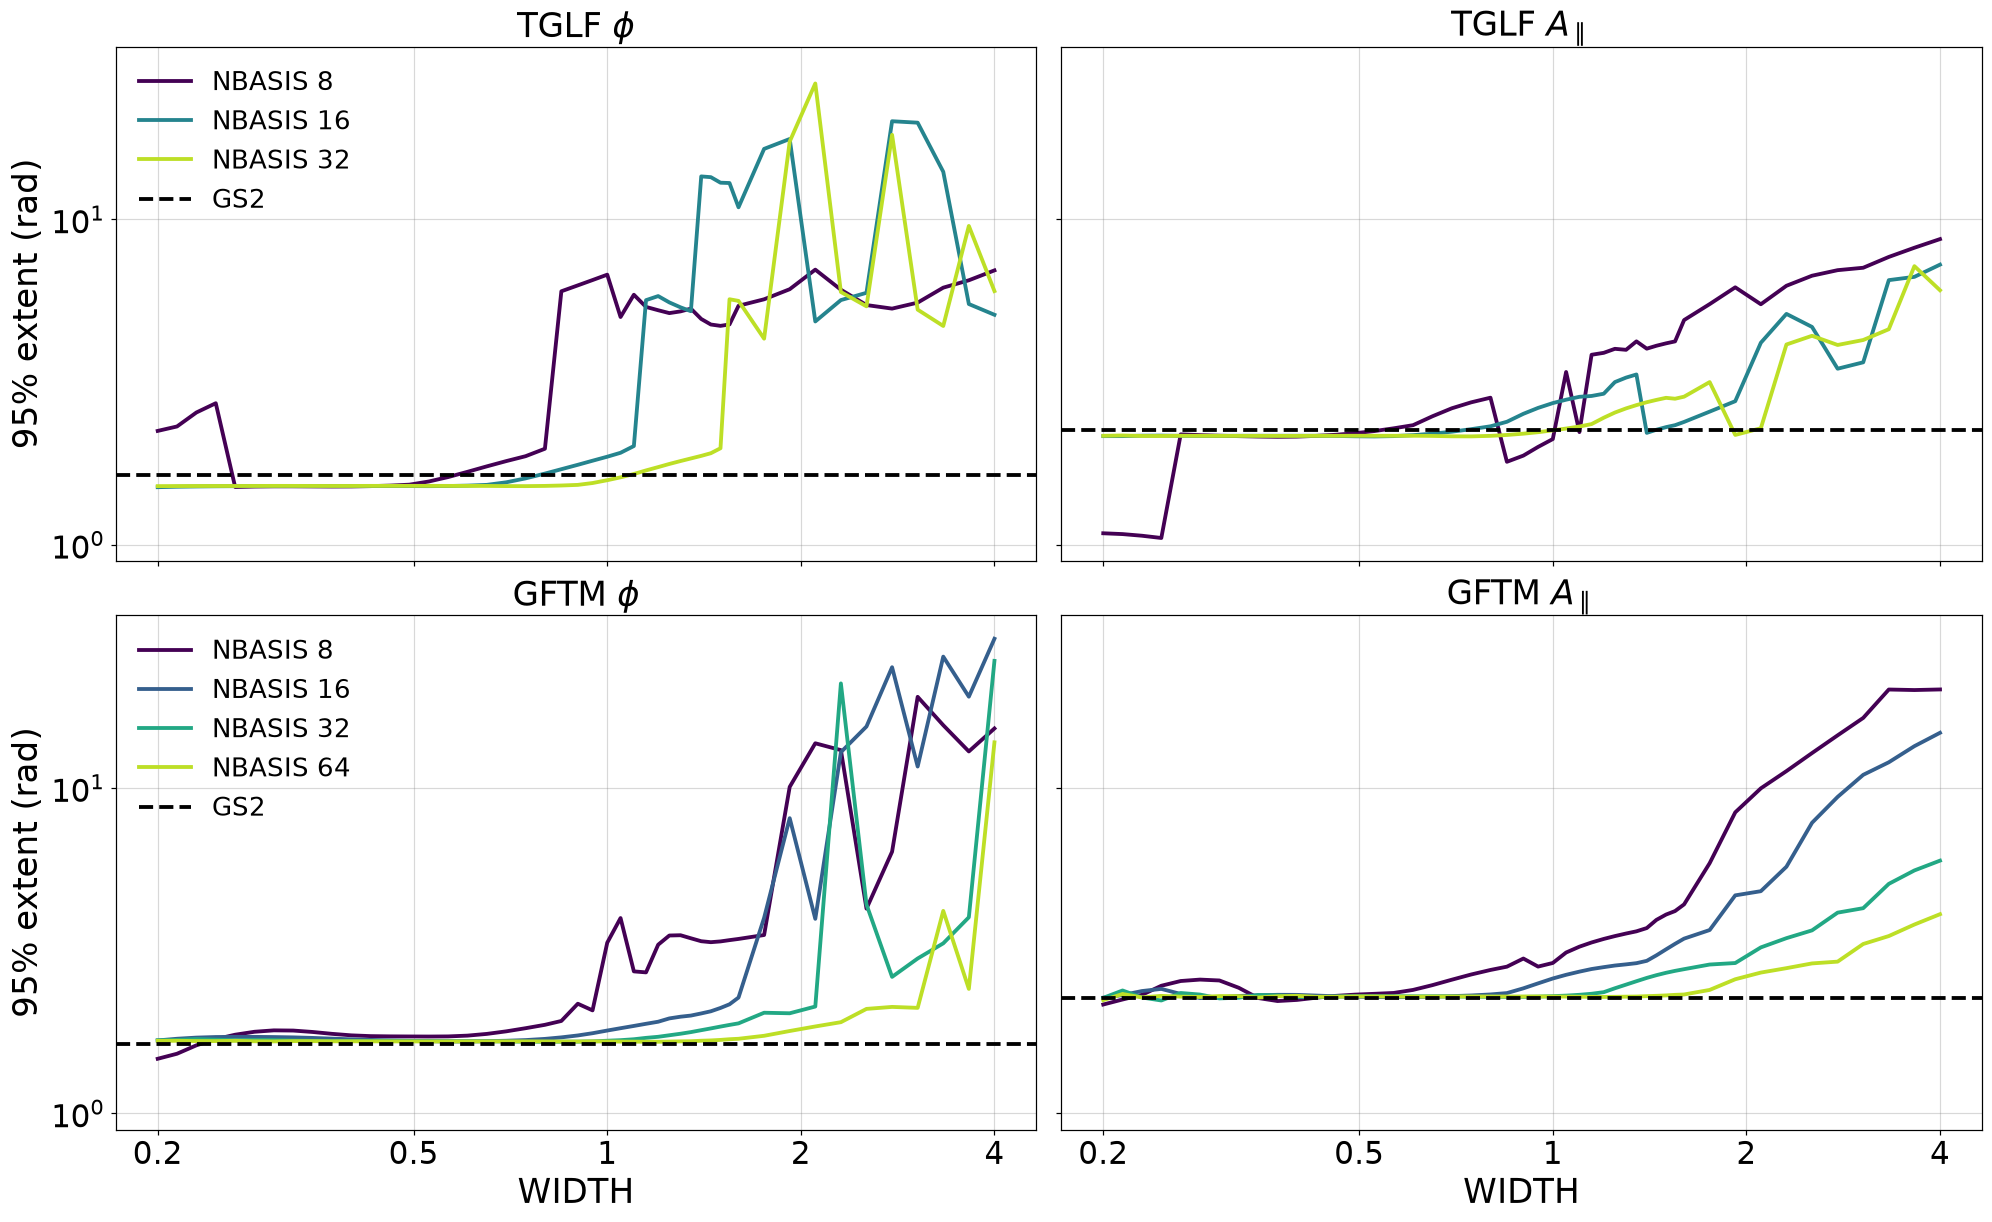

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11), sharex=True, sharey=True)
for row, code in enumerate(leaves):
    nbasis_colours = dict(zip(shown_nbasis[code], plt.cm.viridis(np.linspace(0, 0.9, len(shown_nbasis[code])))))
    for ax, field in zip(axes[row], field_labels):
        for nbasis in shown_nbasis[code]:
            unstable = runs[(runs.code == code) & (runs.nbasis == nbasis) & (runs.gamma > 0)]
            ax.plot(unstable.width, unstable[f"extent_{field}"], color=nbasis_colours[nbasis], label=f"NBASIS {nbasis}")
        ax.axhline(extent_gs2[field], color="k", ls="--", label="GS2")
        ax.set(xscale="log", yscale="log", title=f"{code} {field_labels[field]}")
        log_xticks(ax, [0.2, 0.5, 1, 2, 4])
    axes[row, 0].set_ylabel("95% extent (rad)")
    axes[row, 0].legend(fontsize=17)
for ax in axes[1]:
    ax.set_xlabel("WIDTH")
fig.savefig(plots_dir / "fig_slide18b_single_kbm_extent.png", bbox_inches="tight")
plt.show()